# 05 - Transfer learning (ResNet50, VGG16) and final comparison  
**Transfer learning:** instead of training a huge network from zero, we reuse a network pre-trained on ImageNet (1.2 M images) and only adapt it to our 8 classes.

**Two phases for each network**
1. **Feature extraction** - the pretrained base is *frozen*; only the new classification head is trained.
2. **Fine-tuning** - the last layers of the base are *unfrozen* and trained with a very small learning rate.

> Requires PyTorch + torchvision:  `python -m pip install torch torchvision`
> The first run downloads the ImageNet weights (ResNet50 ~ 100 MB, VGG16 ~ 528 MB) - internet is required.
> A GPU is used automatically if available (CUDA, or Apple MPS); otherwise the CPU is used.
> If you are short of RAM/time, lower `EPOCHS` in `src/common.py` or set `MAX_PER_CLASS` to e.g. 300.

In [1]:
import sys; sys.path.append("..")          # lets the notebook import src/common.py
from src.common import *
import matplotlib.pyplot as plt, numpy as np, pandas as pd
print("Project root:", ROOT)
print("QUICK mode:", QUICK)

Project root: C:\Users\ASUS\Desktop\image_classification_project
QUICK mode: False


> **PyTorch + torchvision required for the next cells (ResNet50 / VGG16).** If they are unavailable, skip to *"3 - Final comparison"* - those cells only need the other notebooks' saved metrics.

In [2]:
import time
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models
from torchvision.models import ResNet50_Weights, VGG16_Weights

torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
                      else "cpu")

X_train, X_test, y_train, y_test = load_split()
# keep images as uint8 NHWC tensors (saves RAM); each batch is converted to float 0..1 NCHW on the fly
Ttr = torch.from_numpy(np.asarray(X_train).astype("uint8"))
Tte = torch.from_numpy(np.asarray(X_test).astype("uint8"))
ytr = torch.tensor(np.asarray(y_train), dtype=torch.long)
yte = torch.tensor(np.asarray(y_test), dtype=torch.long)

# same 85 / 15 train / validation split for both networks
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(Ttr), generator=g); n_val = int(0.15 * len(Ttr))
val_idx, tr_idx = perm[:n_val], perm[n_val:]

BATCH = 64
FINE_TUNE_EPOCHS = 1 if QUICK else 3
USE_WEIGHTS = bool(USE_PRETRAINED)
prep = lambda xb: xb.permute(0, 3, 1, 2).float().div(255.0).to(DEVICE)    # NHWC uint8 -> NCHW float 0..1
print("device:", DEVICE, "| pretrained:", USE_WEIGHTS, "| input size:", TL_SIZE, "| epochs:", EPOCHS)

device: cpu | pretrained: True | input size: 96 | epochs: {'mlp': 30, 'cnn': 25, 'resnet': 8, 'vgg': 8}


## Builder shared by both networks
`64x64 image -> resize to 96x96 -> ImageNet mean/std normalisation -> pretrained base -> global average pooling -> Linear(256) -> ReLU -> Dropout -> Linear(8)`

Like `training=False` in Keras, the **BatchNorm layers of the base always stay in inference mode**, even during fine-tuning.

In [3]:
class Transfer(nn.Module):
    def __init__(self, base, feat_dim):
        super().__init__()
        self.base = base
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.head = nn.Sequential(nn.Linear(feat_dim, 256), nn.ReLU(), nn.Dropout(0.3),
                                  nn.Linear(256, len(CLASSES)))
    def forward(self, x):
        x = F.interpolate(x, size=(TL_SIZE, TL_SIZE), mode="bilinear", align_corners=False)
        x = (x - self.mean) / self.std
        return self.head(self.base(x))
    def train(self, mode=True):
        super().train(mode)
        for m in self.base.modules():                       # keep BatchNorm in inference mode
            if isinstance(m, nn.modules.batchnorm._BatchNorm): m.eval()
        return self

def build_resnet50():
    base = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1 if USE_WEIGHTS else None)
    base.fc = nn.Identity()                                  # -> 2048 pooled features
    return Transfer(base, 2048).to(DEVICE), [base.layer4]    # phase 2 unfreezes layer4 (~ last 30 layers)

def build_vgg16():
    vgg = models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1 if USE_WEIGHTS else None)
    base = nn.Sequential(vgg.features, nn.AdaptiveAvgPool2d(1), nn.Flatten())   # -> 512 pooled features
    return Transfer(base, 512).to(DEVICE), [vgg.features[24:]]                  # features[24:] = block5

def predict_logits(model, T):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(T), 128): out.append(model(prep(T[i:i + 128])).cpu())
    return torch.cat(out)

class _H: pass
def merge_history(h1, h2):
    m = _H(); m.history = {k: h1[k] + h2[k] for k in h1}; return m

def fit(model, lr, epochs, patience=3):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr); lossf = nn.CrossEntropyLoss()
    hist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    best, best_state, wait = float("inf"), None, 0
    for ep in range(epochs):
        model.train(); idx = tr_idx[torch.randperm(len(tr_idx))]; tl = tc = 0
        for i in range(0, len(idx), BATCH):
            b = idx[i:i + BATCH]; xb, yb = prep(Ttr[b]), ytr[b].to(DEVICE)
            opt.zero_grad(); out = model(xb); loss = lossf(out, yb); loss.backward(); opt.step()
            tl += loss.item() * len(b); tc += (out.argmax(1) == yb).sum().item()
        logits = predict_logits(model, Ttr[val_idx]); yv = ytr[val_idx]
        vl = lossf(logits, yv).item(); va = (logits.argmax(1) == yv).float().mean().item()
        hist["loss"].append(tl / len(tr_idx)); hist["accuracy"].append(tc / len(tr_idx))
        hist["val_loss"].append(vl); hist["val_accuracy"].append(va)
        print(f"epoch {ep+1}/{epochs}  loss {hist['loss'][-1]:.3f}  acc {hist['accuracy'][-1]:.3f}  "
              f"val_loss {vl:.3f}  val_acc {va:.3f}")
        if vl < best:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: print("early stopping"); break
    if best_state is not None: model.load_state_dict(best_state)       # restore best weights
    return hist

def train_transfer(model, unfreeze, epochs):
    t = time.time()
    # ---- phase 1: train the head only
    for p in model.base.parameters(): p.requires_grad = False
    print("Phase 1 - feature extraction")
    h1 = fit(model, 1e-3, epochs)
    # ---- phase 2: fine-tune the last layers with a tiny learning rate
    for m in unfreeze:
        for p in m.parameters(): p.requires_grad = True
    print("Phase 2 - fine-tuning")
    h2 = fit(model, 1e-5, FINE_TUNE_EPOCHS)
    return merge_history(h1, h2), time.time() - t

## 1 - ResNet50
![ResNet50](../docs/model_steps/09_resnet50.png)

ResNet's **residual (skip) connections** let very deep networks (50 layers) train well. Phase 2 unfreezes the last residual stage (`layer4`).

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet50-0676ba61.pth


100.0%


parameters: 24,034,632
Phase 1 - feature extraction
epoch 1/8  loss 0.157  acc 0.953  val_loss 0.052  val_acc 0.981
epoch 2/8  loss 0.037  acc 0.989  val_loss 0.027  val_acc 0.990
epoch 3/8  loss 0.021  acc 0.993  val_loss 0.025  val_acc 0.990
epoch 4/8  loss 0.019  acc 0.994  val_loss 0.021  val_acc 0.994
epoch 5/8  loss 0.013  acc 0.996  val_loss 0.021  val_acc 0.995
epoch 6/8  loss 0.011  acc 0.996  val_loss 0.026  val_acc 0.989
epoch 7/8  loss 0.006  acc 0.998  val_loss 0.037  val_acc 0.990
epoch 8/8  loss 0.020  acc 0.993  val_loss 0.023  val_acc 0.994
early stopping
Phase 2 - fine-tuning
epoch 1/3  loss 0.011  acc 0.997  val_loss 0.020  val_acc 0.995
epoch 2/3  loss 0.004  acc 0.998  val_loss 0.027  val_acc 0.992
epoch 3/3  loss 0.002  acc 1.000  val_loss 0.024  val_acc 0.996
saved -> results\figures\history_resnet50.png


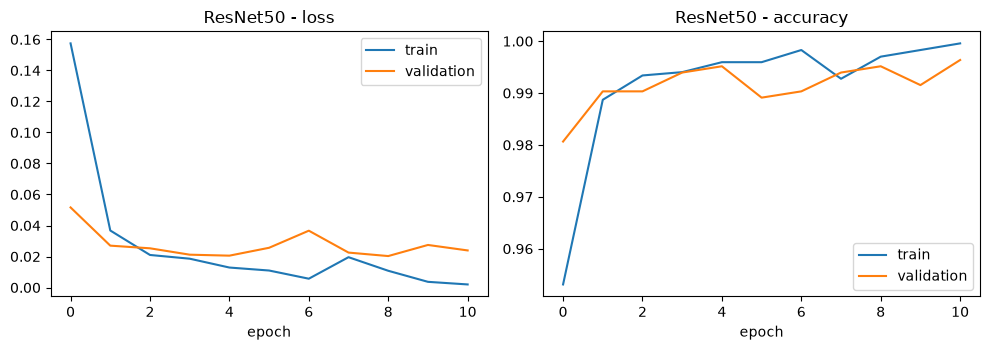

In [4]:
resnet, resnet_unfreeze = build_resnet50()
print("parameters:", f"{sum(p.numel() for p in resnet.parameters()):,}")
h_res, tt = train_transfer(resnet, resnet_unfreeze, epochs=EPOCHS["resnet"])
plot_history(h_res, "ResNet50")

=== ResNet50 ===   accuracy=0.9877  precision=0.9877  recall=0.9877  F1=0.9876
              precision    recall  f1-score   support

    airplane       0.99      0.99      0.99       145
         car       0.99      1.00      1.00       194
         cat       0.96      0.95      0.96       177
         dog       0.98      0.95      0.96       140
      flower       0.98      1.00      0.99       169
       fruit       1.00      1.00      1.00       200
   motorbike       1.00      0.99      1.00       158
      person       1.00      1.00      1.00       197

    accuracy                           0.99      1380
   macro avg       0.99      0.99      0.99      1380
weighted avg       0.99      0.99      0.99      1380

saved -> results\figures\cm_resnet50.png


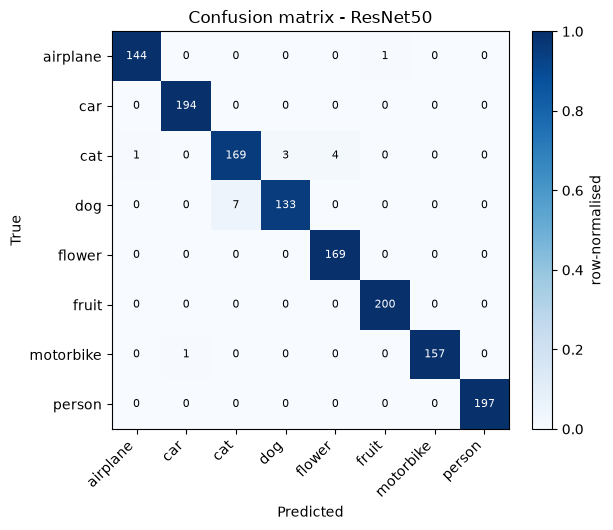

saved -> results\figures\predictions_resnet50.png


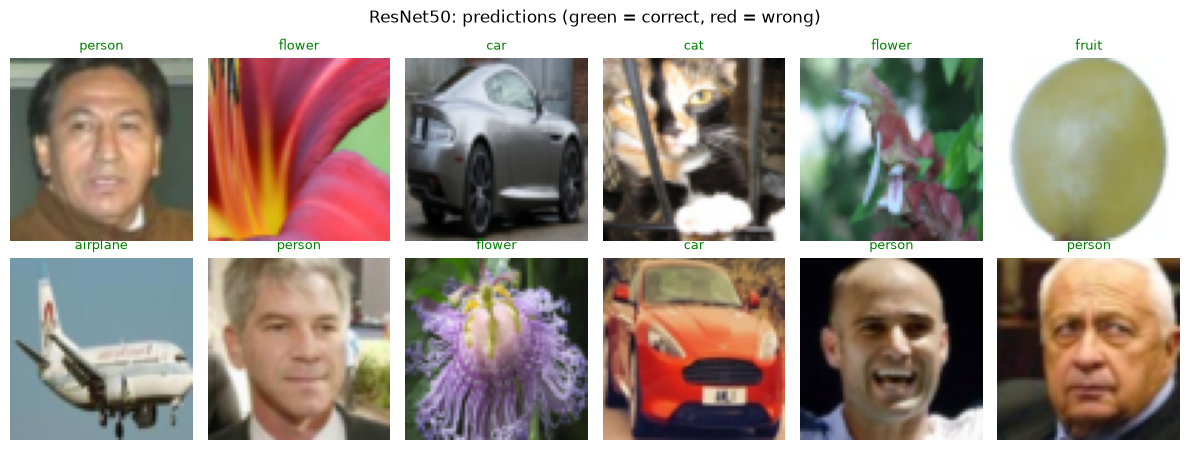

In [5]:
y_pred = predict_logits(resnet, Tte).argmax(1).numpy()
evaluate("ResNet50", "Deep Learning", y_test, y_pred, tt)
show_predictions(X_test, y_test, y_pred, "ResNet50")
torch.save(resnet.state_dict(), MODELS_DIR / "resnet50.pt")      # reload: build_resnet50()[0].load_state_dict(torch.load(path))

## 2 - VGG16
![VGG16](../docs/model_steps/10_vgg16.png)

VGG16 is a plain stack of 3x3 convolutions in 5 blocks. Phase 2 unfreezes the last convolution block (`block5`).

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100.0%


parameters: 14,848,072
Phase 1 - feature extraction
epoch 1/8  loss 0.251  acc 0.952  val_loss 0.045  val_acc 0.985
epoch 2/8  loss 0.037  acc 0.989  val_loss 0.039  val_acc 0.983
epoch 3/8  loss 0.022  acc 0.993  val_loss 0.035  val_acc 0.990
epoch 4/8  loss 0.017  acc 0.996  val_loss 0.034  val_acc 0.989
epoch 5/8  loss 0.008  acc 0.999  val_loss 0.031  val_acc 0.992
epoch 6/8  loss 0.010  acc 0.997  val_loss 0.032  val_acc 0.990
epoch 7/8  loss 0.006  acc 0.999  val_loss 0.034  val_acc 0.990
epoch 8/8  loss 0.006  acc 0.999  val_loss 0.038  val_acc 0.989
early stopping
Phase 2 - fine-tuning
epoch 1/3  loss 0.005  acc 0.998  val_loss 0.031  val_acc 0.992
epoch 2/3  loss 0.002  acc 0.999  val_loss 0.034  val_acc 0.990
epoch 3/3  loss 0.001  acc 1.000  val_loss 0.034  val_acc 0.992
saved -> results\figures\history_vgg16.png


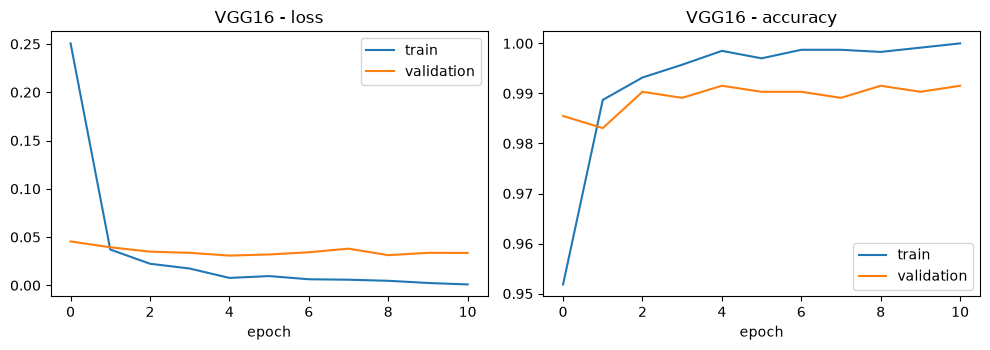

In [6]:
del resnet; 
if DEVICE.type == "cuda": torch.cuda.empty_cache()
vgg, vgg_unfreeze = build_vgg16()
print("parameters:", f"{sum(p.numel() for p in vgg.parameters()):,}")
h_vgg, tt = train_transfer(vgg, vgg_unfreeze, epochs=EPOCHS["vgg"])
plot_history(h_vgg, "VGG16")

=== VGG16 ===   accuracy=0.9848  precision=0.9848  recall=0.9848  F1=0.9848
              precision    recall  f1-score   support

    airplane       0.99      1.00      1.00       145
         car       1.00      0.99      1.00       194
         cat       0.94      0.95      0.95       177
         dog       0.95      0.93      0.94       140
      flower       0.99      0.99      0.99       169
       fruit       1.00      1.00      1.00       200
   motorbike       1.00      1.00      1.00       158
      person       1.00      1.00      1.00       197

    accuracy                           0.98      1380
   macro avg       0.98      0.98      0.98      1380
weighted avg       0.98      0.98      0.98      1380

saved -> results\figures\cm_vgg16.png


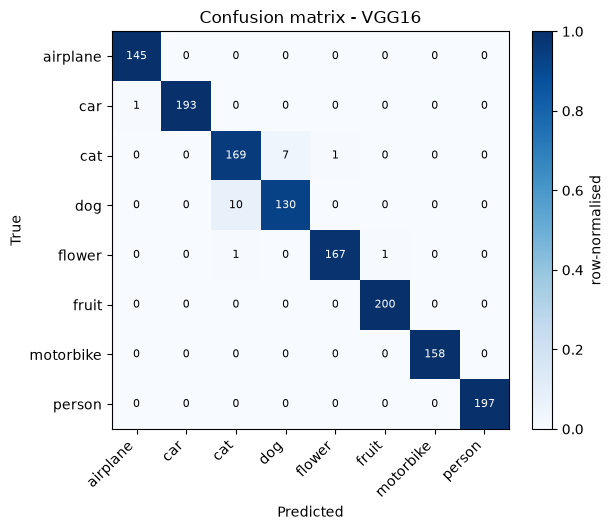

saved -> results\figures\predictions_vgg16.png


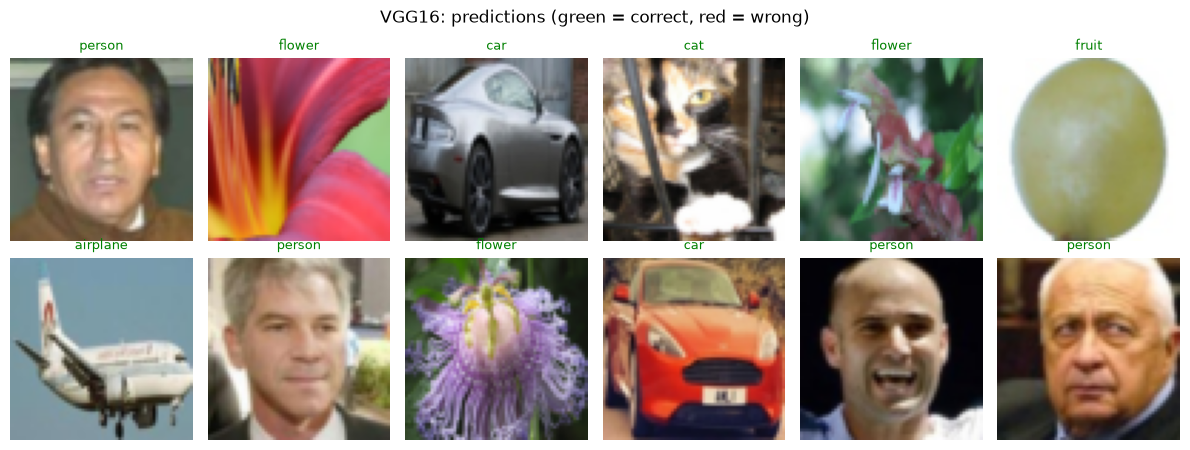

In [7]:
y_pred = predict_logits(vgg, Tte).argmax(1).numpy()
evaluate("VGG16", "Deep Learning", y_test, y_pred, tt)
show_predictions(X_test, y_test, y_pred, "VGG16")
torch.save(vgg.state_dict(), MODELS_DIR / "vgg16.pt")

## 3 - Final comparison of all ten models
Everything is read from `results/metrics/*.json` (written by notebooks 03, 04, 05) and merged into **`results/all_models_comparison.csv`**.

In [8]:
df = compare()
expected = {"SVM", "KNN", "Random Forest", "Decision Tree", "Logistic Regression", "Naive Bayes",
            "MLP", "CNN", "ResNet50", "VGG16"}
missing = expected - set(df["model"])
if missing: print("WARNING - not trained yet:", sorted(missing))
display(df.round(4))
print("Saved ->", (ROOT / "results" / "all_models_comparison.csv").relative_to(ROOT))

,model,family,accuracy,precision,recall,f1_score,train_time_s
0,ResNet50,Deep Learning,0.9877,0.9877,0.9877,0.9876,353.5
1,VGG16,Deep Learning,0.9848,0.9848,0.9848,0.9848,767.4
2,CNN,Deep Learning,0.9312,0.9360,0.9312,0.9316,570.1
3,SVM,Traditional ML,0.8920,0.8923,0.8920,0.8920,8.7
4,Random Forest,Traditional ML,0.8464,0.8445,0.8464,0.8354,2.6
5,Logistic Regression,Traditional ML,0.8304,0.8316,0.8304,0.8310,6.3
6,Naive Bayes,Traditional ML,0.8217,0.8326,0.8217,0.8256,0.0
7,MLP,Deep Learning,0.8022,0.8009,0.8022,0.7981,259.2
8,KNN,Traditional ML,0.7638,0.8208,0.7638,0.7295,0.0
9,Decision Tree,Traditional ML,0.6290,0.6426,0.6290,0.6348,5.5


Saved -> results\all_models_comparison.csv


saved -> results\figures\all_models_comparison.png


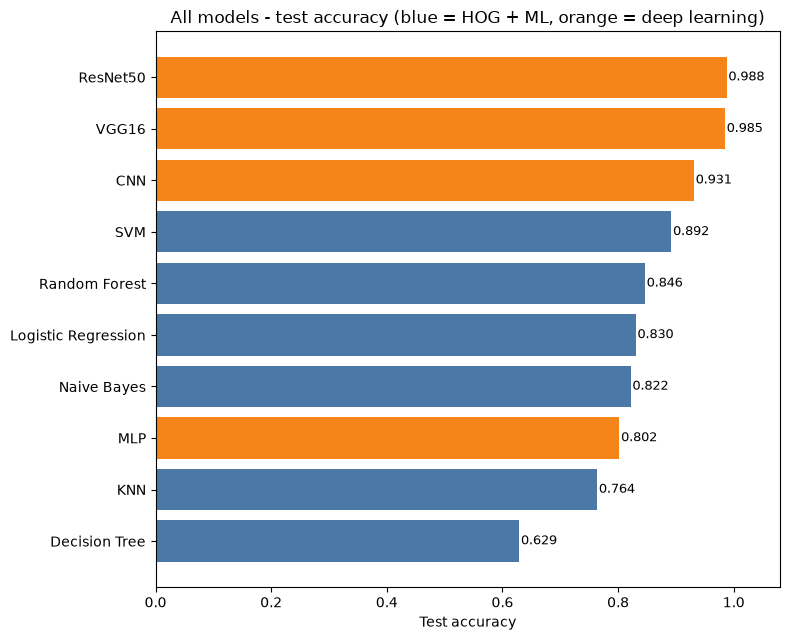

In [9]:
plot_comparison(df)

saved -> results\figures\05_metrics_and_time.png


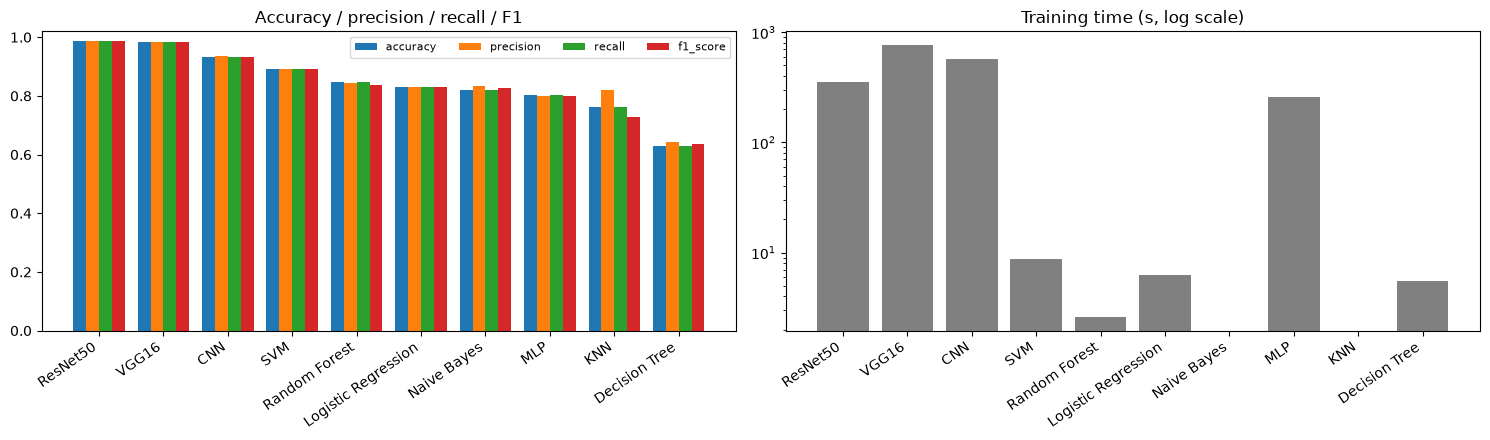

In [10]:
# metrics side by side + training time
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
d = df.sort_values("f1_score", ascending=False); x = np.arange(len(d)); w = 0.2
for i, m in enumerate(["accuracy", "precision", "recall", "f1_score"]):
    ax[0].bar(x + (i - 1.5) * w, d[m], w, label=m)
ax[0].set_xticks(x); ax[0].set_xticklabels(d["model"], rotation=35, ha="right"); ax[0].set_ylim(0, 1.02)
ax[0].legend(ncol=4, fontsize=8); ax[0].set_title("Accuracy / precision / recall / F1")
ax[1].bar(d["model"], d["train_time_s"], color="gray"); ax[1].set_yscale("log")
ax[1].set_title("Training time (s, log scale)"); plt.setp(ax[1].get_xticklabels(), rotation=35, ha="right")
plt.tight_layout(); save_fig("05_metrics_and_time.png"); plt.show()

## How to read the results
* Compare **F1-score** rather than only accuracy if some classes are rarer.
* Look at each model's confusion matrix in `results/figures/cm_*.png` to see *which classes get confused* (e.g. cat vs dog).
* Typical pattern: HOG + SVM is the strongest traditional model; Naive Bayes and Decision Tree are the weakest; transfer learning (ResNet50 / VGG16) usually gives the best accuracy; MLP sits between the traditional models and the CNN.
  **Your own numbers are what count - report them from the table above.**
* Trade-off: deep models need more time/RAM; traditional models train in seconds-minutes.